*Draft for review.*

# The georvq Tessera codec (release tessera-v2)

The TESSERA annual embeddings, as geotessera distributes them, come as
0.1 degree tiles of about 1100 x 970 pixels at 10 m, each holding 128
int8 bands and a float32 scale per pixel (the embedding is `q * scale`),
about 142 MB per tile. The tessera-v2 release codes each tile as one
Zarr store of about 2.9 MB that can be read at 42 rates, from 0.23 to
9.8 bits per pixel, by window, over HTTP. The reader returns float32
embeddings in geotessera's dequantised units, with zero vectors at
nodata, and `georvq.tessera.v2.to_geotessera` turns them back into
geotessera's int8 codes and per-pixel scales, so code written for the
source tiles can read these stores instead.

This notebook opens a coded tile, compares its reconstructions with the
source at several rates, measures what reads cost in bytes, requests
and time, and repeats two common analyses (similarity search and
clustering) on source and reconstruction. Errors are given as the
relative L2 error of the 128-band vector, `||decoded - source|| /
||source||` per pixel, which is the statistic the release measures and
stores. The release layer is `georvq/tessera/v2.py`, and the store
layout is in `docs/GEORVQ_ZARR.md`.

## Configuration

`DATA_ROOT` holds the coded stores (`{year}/grid_{lon}_{lat}.georvq.zarr`)
and their index. It can be a local directory or an HTTP URL, and points
at the sample on Hugging Face. `STORAGE_OPTIONS` go to fsspec when the
stores are read by URL, for example a token for a private repository.
`SOURCE_ROOT` holds the source tiles in the layout of Tessera's bucket
(`global_0.1_degree_representation/{year}/grid_{lon}_{lat}/`), used here
only for comparison.

The sample (`earth-compress/georvq-tessera-v2-sample`) and the bundle
(`earth-compress/georvq-tessera-v2`) are not yet published, so the
marked lines in the cell below point the notebook at local copies of
both. Deleting them switches the stores and the bundle to Hugging Face,
with no other change. Tessera's public bucket, and its mirror on Source
Cooperative, have returned 404 since 19 October 2026, so `SOURCE_ROOT`
points at local copies of the four source tiles until the bucket serves
them again.

The codec weights are not in the stores. On the first pixel read,
`georvq.open` finds the bundle the store's header names: in
`$GEORVQ_TESSERA_BUNDLE`, in the cache at
`~/.cache/georvq/bundles/<bitstream_id>/`, or by downloading it from the
Hugging Face release (`earth-compress/georvq-tessera-v2`, about 990 MB,
of which 530 MB is the ONNX export). On a machine with a GPU the torch
backend uses it; everything below also runs on CPU, more slowly (a
whole tile takes about 15 s to decode on 16 CPU threads).

In [1]:
import os
from rasterio.windows import Window

DATA_ROOT = "https://huggingface.co/datasets/earth-compress/georvq-tessera-v2-sample/resolve/main"
STORAGE_OPTIONS = None    # e.g. {"headers": {"Authorization": "Bearer <token>"}}
SOURCE_ROOT = "https://s3.us-west-2.amazonaws.com/tessera-embeddings/v1"
# a large file already on Hugging Face, to measure latency and throughput there
PROBE_URL = "https://huggingface.co/earth-compress/georvq-ae-v2/resolve/main/weights.npz"

# ---- local copies, until the sample and the bundle are published -----------
# Delete the next two lines once earth-compress/georvq-tessera-v2-sample and
# earth-compress/georvq-tessera-v2 are public on Hugging Face.
DATA_ROOT = "/data/georvq-releases/tessera-v2/sample"
os.environ["GEORVQ_TESSERA_BUNDLE"] = "/data/georvq-releases/tessera-v2/bundle"
# Tessera's bucket has returned 404 since 19 October 2026; delete this line
# when it serves tiles again.
SOURCE_ROOT = os.path.expanduser("~/.cache/georvq_lab/geotessera")
# ---------------------------------------------------------------------------

TILE = "2024/grid_-9.35_30.15"              # south-east of Agadir, Morocco
# a 512 px window of TILE, inside one 1024 px chunk of the fine tier
WINDOW = Window(col_off=256, row_off=256, width=512, height=512)

# Speed section: with a local DATA_ROOT, the store is served through a
# range server that adds the latency and throughput measured to Hugging
# Face; with a URL, the hosted store is read as it is. The source is
# treated the same way by SOURCE_ROOT.
SIMULATE_REMOTE = not DATA_ROOT.startswith(("http://", "https://"))

In [2]:
import sys, time, tempfile, urllib.request, json, io
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, ListedColormap
from matplotlib.patches import Rectangle
import rasterio
from rasterio.warp import transform_bounds
import rasterio.windows

import pyarrow.parquet as pq
import georvq
from georvq.inference.store_codec import quality_value
from georvq.inference.records import Trace
from georvq.tessera.v2 import GeotesseraTile, raw_valid, to_geotessera
import ae_demo_http

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 9.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "normal", "legend.frameon": False})
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
    "#6250d6", "#e34948")
GREY, INK = "#8a8984", "#52514e"
NODATA_RGB = (0.86, 0.86, 0.84)


REMOTE = DATA_ROOT.startswith(("http://", "https://"))


def data_url(tile):
    return f"{DATA_ROOT}/{tile}.georvq.zarr"


def open_tile(tile, **kw):
    return georvq.open(data_url(tile), storage_options=STORAGE_OPTIONS if REMOTE else None, **kw)


def source_paths(tile):
    """The tile's embedding and scale files, relative to SOURCE_ROOT."""
    year, name = tile.split("/")
    d = f"global_0.1_degree_representation/{year}/{name}/{name}"
    return d + ".npy", d + "_scales.npy"


def source_tile(tile):
    """The geotessera tile under SOURCE_ROOT: int8 codes `q` (128, rows, cols),
    scales `s` (rows, cols), and the georeferencing of its landmask."""
    year, name = tile.split("/")
    lon, lat = (float(v) for v in name.removeprefix("grid_").split("_"))
    return GeotesseraTile(year, lon, lat, root=SOURCE_ROOT)


# the tile index, read once: store sizes, source sizes and the bytes of whole-tile reads
idx_path = f"{DATA_ROOT}/tessera_georvq_index.parquet"
if REMOTE:
    req = urllib.request.Request(idx_path, headers=(STORAGE_OPTIONS or {}).get("headers", {}))
    index = pq.read_table(io.BytesIO(urllib.request.urlopen(req).read()))
else:
    index = pq.read_table(idx_path)


def tile_row(tile):
    return next(r for r in index.to_pylist() if r["path"].endswith(f"{tile}.georvq.zarr"))


def store_size(tile):
    r = tile_row(tile)
    return r["store_bytes"] + r["metadata_bytes"]


def source_size(tile):
    """Bytes of the tile's embedding and scale files, from geotessera's manifest."""
    r = tile_row(tile)
    return r["grid_size"] + r["scales_size"]


# zarr-python makes the requests, so they are counted by a local server
# between it and DATA_ROOT, which forwards each one and records it
if REMOTE:
    METER, meter, _ = ae_demo_http.serve(upstream=DATA_ROOT,
                                         headers=(STORAGE_OPTIONS or {}).get("headers"))
else:
    METER, meter, _ = ae_demo_http.serve(root=DATA_ROOT)


def metered(tile):
    """The store's URL through the recording server."""
    return f"{METER}/{tile}.georvq.zarr"


def vec(a):
    """float32 (128, rows, cols) as read -> (rows, cols, 128); NaN at nodata,
    where the reader returns zero vectors."""
    x = np.moveaxis(np.asarray(a, np.float32), 0, -1).copy()
    x[(x == 0).all(-1)] = np.nan
    return x


def src_vec(t):
    """A geotessera tile -> its dequantised embeddings q * scale as
    (rows, cols, 128); NaN where the pixel is invalid."""
    x = np.moveaxis(t.q, 0, -1).astype(np.float32) * t.s[..., None]
    x[~raw_valid(t.q, t.s)] = np.nan
    return x


def err(x, y):
    """Per-pixel relative L2 error ||y - x|| / ||x|| of field y against field x."""
    return np.linalg.norm(y - x, axis=-1) / np.maximum(np.linalg.norm(x, axis=-1), 1e-6)


class PCARGB:
    """The first three principal components of a field, as RGB."""
    def fit(self, u, n=200_000):
        X = u[np.isfinite(u[..., 0])]
        X = X[np.random.default_rng(0).choice(len(X), min(n, len(X)), replace=False)]
        self.mean = X.mean(0)
        self.axes = np.linalg.svd(X - self.mean, full_matrices=False)[2][:3]
        P = (X - self.mean) @ self.axes.T
        self.lo, self.hi = np.percentile(P, [1, 99], axis=0)
        return self

    def __call__(self, u):
        P = (np.nan_to_num(u) - self.mean) @ self.axes.T
        rgb = np.clip((P - self.lo) / (self.hi - self.lo), 0, 1)
        rgb[~np.isfinite(u[..., 0])] = NODATA_RGB
        return rgb


def corners(transform, h, w):
    xs, ys = zip(*[transform * (c, r) for c in (0, w) for r in (0, h)])
    return min(xs), min(ys), max(xs), max(ys)


def show(ax, img, transform, ticks=True, **kw):
    """imshow north-up in projected km, whatever the row order."""
    h, w = img.shape[:2]
    x0, y0, x1, y1 = corners(transform, h, w)
    im = ax.imshow(img[::-1] if transform.e > 0 else img,
                   extent=[x0 / 1e3, x1 / 1e3, y0 / 1e3, y1 / 1e3], **kw)
    if ticks:
        ax.set_xlabel("easting (km)")
        ax.set_ylabel("northing (km)")
    else:
        ax.set_xticks([]); ax.set_yticks([])
    return im


def lonlat(crs, transform, h, w):
    w_, s_, e_, n_ = transform_bounds(crs, "EPSG:4326", *corners(transform, h, w))
    ns = lambda v: f"{abs(v):.2f}°{'N' if v >= 0 else 'S'}"
    ew = lambda v: f"{abs(v):.2f}°{'E' if v >= 0 else 'W'}"
    return f"{ns(s_)} to {ns(n_)}, {ew(w_)} to {ew(e_)}"


def mb(n):
    return f"{n / 1e6:,.2f} MB"

## Opening a store

`georvq.open` opens the store with zarr-python, which reads the
group's zarr.json with one request: the georeferencing, the codec
header and the metadata of every array. The dataset it returns has the
attributes of a rasterio dataset (`crs`, `transform`, `width`, `height`,
`count`, `dtypes`, `nodata`, `profile`, `tags()`, `block_windows()`),
with the georeferencing of the tile's landmask GeoTIFF in geotessera's
bucket, and its `read` takes rasterio's `window` argument, plus
`quality`, the rate to decode at.

In [3]:
path = data_url(TILE)
ds = open_tile(TILE)
meter.clear()
georvq.open(metered(TILE))
open_req, open_bytes = len(meter.events), sum(e["bytes"] for e in meter.events)

print(f"{'store':<12}{path}")
print(f"{'crs':<12}{ds.crs.to_string()}")
print(f"{'size':<12}{ds.width} x {ds.height} px, {ds.count} bands of {ds.dtypes[0]}, nodata {ds.nodata}")
print(f"{'transform':<12}{tuple(ds.transform)[:6]}")
print(f"{'row order':<12}{'bottom-up, as the source' if ds.transform.e > 0 else 'north-up'}")
print(f"{'extent':<12}{lonlat(ds.crs, ds.transform, ds.height, ds.width)}")
print(f"{'codec':<12}bitstream {ds.header['codec']['bitstream_id']}, release {ds.header['codec']['release']['name']}")
print(f"{'opened with':<12}{open_req} request, {mb(open_bytes)}")

store       /data/georvq-releases/tessera-v2/sample/2024/grid_-9.35_30.15.georvq.zarr
crs         EPSG:32629
size        966 x 1111 px, 128 bands of float32, nodata 0.0
transform   (10.0, 0.0, 461459.5069982938, 0.0, -10.0, 3341014.9148636176)
row order   north-up
extent      30.10°N to 30.20°N, 9.40°W to 9.30°W
codec       bitstream cdadaa29e3b5f45a, release tessera-v2
opened with 1 request, 0.05 MB


The header lists the rates the store supports. A rate is a depth tuple:
how many residual levels of each of the three tiers to decode (coarse,
64 px cells; mid, 16 px; fine, 4 px). The coarse tier starts at 4
levels, the fewest the model decodes, which gives 42 rungs. `bits_px`
counts every bit read per pixel, the transmitted window mean included,
and `whole-tile MB` is what reading the entire tile at that rung
fetches. The 20 coarse levels are stored in one record with the mean,
so every coarse rung fetches the same bytes.

In [4]:
import pandas as pd

rb = {r["rung"]: r["bytes"] for r in tile_row(TILE)["rungs"]}
ladder = pd.DataFrame([{"rung": "-".join(map(str, r["tuple"])),
                        "bits/window": r["bits_window"],
                        "bits/px": round(r["bits_px"], 3),
                        "whole-tile MB": round(rb["-".join(map(str, r["tuple"]))] / 1e6, 3)}
                       for r in ds.header["rungs"]])
src_bytes = source_size(TILE)
print(f"coded store {mb(store_size(TILE))}, source tile {mb(src_bytes)} (codes and scales), "
      f"ratio {src_bytes / store_size(TILE):.0f} to 1")
ladder.set_index("rung").T

coded store 2.94 MB, source tile 141.67 MB (codes and scales), ratio 48 to 1


rung,4-0-0,5-0-0,6-0-0,7-0-0,8-0-0,9-0-0,10-0-0,11-0-0,12-0-0,13-0-0,...,20-13-3,20-13-4,20-13-5,20-13-6,20-13-7,20-13-8,20-13-9,20-13-10,20-13-11,20-13-12
bits/window,928.000,936.000,944.000,952.000,960.000,968.000,976.000,984.000,992.000,1000.000,...,12560.000,15632.000,18704.000,21776.000,24848.000,27920.000,30992.000,34064.000,37136.000,40208.000
bits/px,0.227,0.229,0.230,0.232,0.234,0.236,0.238,0.240,0.242,0.244,...,3.066,3.816,4.566,5.316,6.066,6.816,7.566,8.316,9.066,9.816
whole-tile MB,0.137,0.137,0.137,0.137,0.137,0.137,0.137,0.137,0.137,0.137,...,1.020,1.216,1.413,1.610,1.806,2.003,2.199,2.396,2.593,2.789


## What the embeddings look like

Each pixel is a 128-dimensional vector. To show a field of them, the
figures project onto its first three principal components and use those
as red, green and blue. The projection is fitted on the source tile,
and the same projection is applied to every reconstruction, so equal
colours mean equal embeddings. The white square is the 512 px window
used for the reads further down.

decoded (128, 1111, 966) float32 in 4.2 s on cuda:0


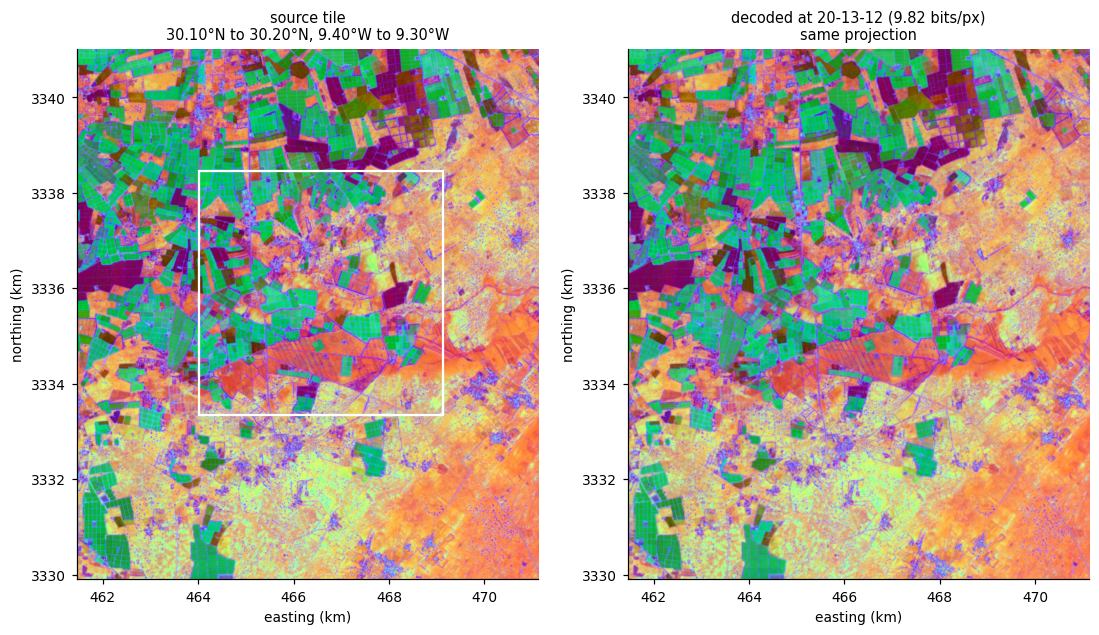

In [5]:
src = source_tile(TILE)
assert src.crs.to_epsg() == ds.crs.to_epsg()
assert np.allclose(src.transform, tuple(ds.transform)[:6]) and (src.height, src.width) == ds.shape
x_ref = src_vec(src)
valid_ref = np.isfinite(x_ref[..., 0])

t = time.perf_counter()
full = ds.read()                                          # quality=None: full depth, 20-13-12
print(f"decoded {full.shape} {full.dtype} in {time.perf_counter() - t:.1f} s "
      f"on {getattr(ds.codec, 'device', 'cpu')}")

pca = PCARGB().fit(x_ref)
win_t = rasterio.windows.transform(WINDOW, ds.transform)

fig, ax = plt.subplots(1, 2, figsize=(10, 5.6), constrained_layout=True)
show(ax[0], pca(x_ref), ds.transform)
x0, y0, x1, y1 = corners(win_t, WINDOW.height, WINDOW.width)
ax[0].add_patch(Rectangle((x0 / 1e3, y0 / 1e3), (x1 - x0) / 1e3, (y1 - y0) / 1e3,
                          fill=False, ec="white", lw=1.5))
ax[0].set_title(f"source tile\n{lonlat(ds.crs, ds.transform, ds.height, ds.width)}")
show(ax[1], pca(vec(full)), ds.transform)
ax[1].set_title(f"decoded at 20-13-12 ({ds.header['rungs'][-1]['bits_px']:.2f} bits/px)\nsame projection")
plt.show()

## The rate ladder

The cell below decodes the tile at every rung and scores each against
the source by the per-pixel relative L2 error. The figure shows a 384 px
crop of six rungs: the coarse tier alone (`4-0-0`, `20-0-0`), the mid
tier added (`20-6-0`, `20-13-0`) and fine levels on top (`20-13-3`,
`20-13-12`), with the error maps below on a log scale.

In [6]:
LADDER = ["4-0-0", "20-0-0", "20-6-0", "20-13-0", "20-13-3", "20-13-12"]
dec, scores = {}, []
t_all = time.perf_counter()
for r in ds.header["rungs"]:
    q = "-".join(map(str, r["tuple"]))
    a = ds.read(quality=q)
    e = err(x_ref, vec(a))[valid_ref]
    scores.append({"rung": q, "bits_px": r["bits_px"], "mean": e.mean(),
                   "p99": np.quantile(e, 0.99)})
    if q in LADDER:
        dec[q] = a
scores = pd.DataFrame(scores).set_index("rung")
print(f"{len(scores)} decodes of the tile in {time.perf_counter() - t_all:.1f} s")
scores.loc[LADDER].style.format({"bits_px": "{:.3f}", "mean": "{:.4f}", "p99": "{:.4f}"})

42 decodes of the tile in 51.5 s


,bits_px,mean,p99
rung,,,
4-0-0,0.227,0.4576,0.8694
20-0-0,0.258,0.4297,0.8178
20-6-0,0.516,0.3525,0.6624
20-13-0,0.816,0.3294,0.6176
20-13-3,3.066,0.2775,0.4803
20-13-12,9.816,0.2352,0.3882


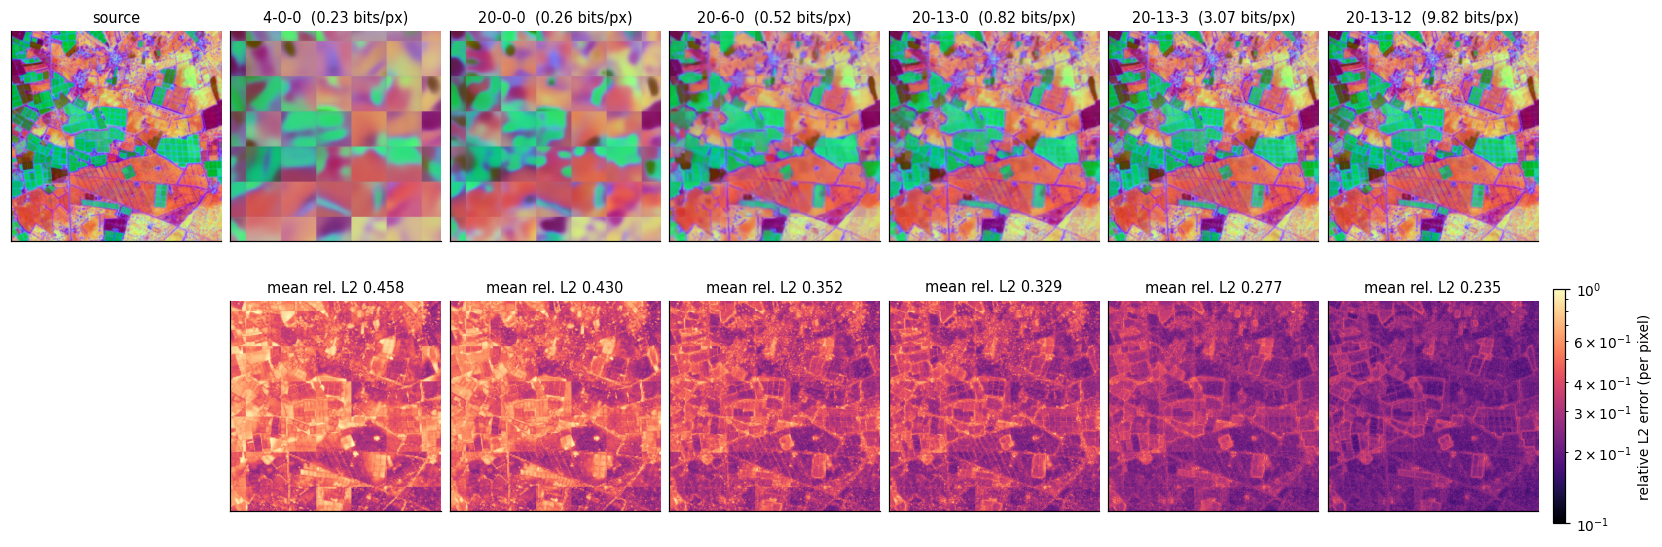

In [7]:
crop = np.s_[364:748, 291:675]          # rows and columns of the tile
crop_t = rasterio.windows.transform(Window(291, 364, 384, 384), ds.transform)
fig, ax = plt.subplots(2, 7, figsize=(15, 4.9), constrained_layout=True)
show(ax[0, 0], pca(x_ref[crop]), crop_t, ticks=False)
ax[0, 0].set_title("source")
ax[1, 0].axis("off")
norm = LogNorm(0.1, 1)
for k, q in enumerate(LADDER, 1):
    u = vec(dec[q][(slice(None),) + crop])
    show(ax[0, k], pca(u), crop_t, ticks=False)
    ax[0, k].set_title(f"{q}  ({scores.loc[q, 'bits_px']:.2f} bits/px)")
    im = show(ax[1, k], np.maximum(err(x_ref[crop], u), 1e-3), crop_t, ticks=False,
              cmap="magma", norm=norm)
    ax[1, k].set_title(f"mean rel. L2 {scores.loc[q, 'mean']:.3f}")
fig.colorbar(im, ax=ax[1, :], shrink=0.9, label="relative L2 error (per pixel)", pad=0.01)
plt.show()

The curve puts the 42 rungs on one axis. The blue points are measured
on this tile here. The orange points come from the store's quality
array, which holds, for every 64 px window and every rung, the mean and
99th percentile of the relative L2 error measured when the tile was
encoded; they are averaged over the tile's valid pixels and need no
decoding. Both cover the whole tile, so the two curves should agree to
within the coding of the quality values, which steps by 7.5% in error.
Coarse levels cost 8 bits per window, mid levels 176 and fine levels
3,072, which gives the three slopes.

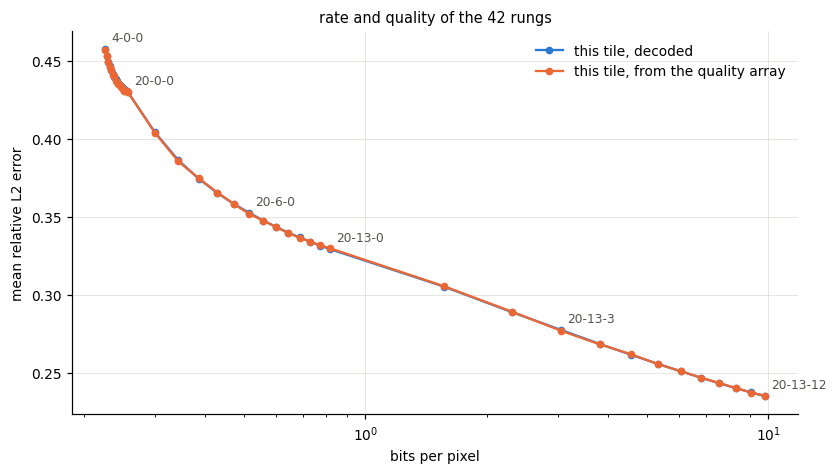

largest difference between the curves: 0.2%


In [8]:
W = ds.window_px
gh, gw = -(-ds.height // W), -(-ds.width // W)              # the last row and column are partial
n_r = len(ds.rungs)
qh = ds.header["quality"]
qc = ds.quality_codes(0, gh, 0, gw)                          # north-up window grid
mask = ds.dataset_mask() > 0
mask_p = np.zeros((gh * W, gw * W), bool)
mask_p[:ds.height, :ds.width] = mask
count = mask_p.reshape(gh, W, gw, W).sum((1, 3))
tile_mean = (quality_value(qc[..., :n_r], qh["scale"], qh["offset"])
             * count[..., None]).sum((0, 1)) / count.sum()

fig, ax = plt.subplots(figsize=(7.5, 4.2), constrained_layout=True)
bpp = scores["bits_px"].values
ax.plot(bpp, scores["mean"], "-o", color=BLUE, ms=4, lw=1.5, label="this tile, decoded")
ax.plot(bpp, tile_mean, "-o", color=ORANGE, ms=4, lw=1.5, label="this tile, from the quality array")
for q in LADDER:
    i = list(scores.index).index(q)
    ax.annotate(q, (bpp[i], scores["mean"].iloc[i]), textcoords="offset points",
                xytext=(4, 5), fontsize=8, color=INK)
ax.set_xscale("log")
ax.set_xlabel("bits per pixel"); ax.set_ylabel("mean relative L2 error")
ax.grid(True, which="major", color="#e4e3df", lw=0.6)
ax.legend()
ax.set_title(f"rate and quality of the {n_r} rungs")
plt.show()
print(f"largest difference between the curves: "
      f"{np.max(np.abs(tile_mean / scores['mean'].values - 1)):.1%}")

## What reads cost

Each read below opens the store afresh, so nothing is cached, and counts
the requests zarr-python makes after the open and the bytes they fetch,
as the recording server between it and `DATA_ROOT` sees them. The source
column is what geotessera fetches for the same read: it downloads a
tile's embedding and scale files whole, whatever part of the tile is
wanted. A client making range requests into the `.npy` files could
fetch less, since they are stored row by row, but would still need
whole rows of the tile for any window. The three whole-tile rows fetch
the records without decoding them.

In [9]:
def cost(fn, tile=TILE):
    with georvq.open(metered(tile), codec=ds.codec) as d:
        meter.clear()
        fn(d)
        ev = list(meter.events)
        return len(ev), sum(e["bytes"] for e in ev)


px = Window(WINDOW.col_off + 200, WINDOW.row_off + 200, 1, 1)
reads = [("one pixel at 20-13-12", lambda d: d.read(window=px, quality="20-13-12"))]
for q in ["20-0-0", "20-13-0", "20-13-3", "20-13-12"]:
    reads.append((f"512 px window at {q}", lambda d, q=q: d.read(window=WINDOW, quality=q)))
for q in [(20, 0, 0), (20, 13, 0), (20, 13, 12)]:
    reads.append((f"whole tile at {'-'.join(map(str, q))}",
                  lambda d, q=q: d.reader.read(0, gh, 0, gw, depths=list(q))))

costs = pd.DataFrame([dict(zip(("read", "requests", "bytes"), (name,) + cost(fn)),
                           source_bytes=src_bytes)
                      for name, fn in reads]).set_index("read")
costs["source / georvq"] = (costs["source_bytes"] / costs["bytes"]).round(1)
print(f"open: {open_req} request, {mb(open_bytes)} of metadata")
costs

open: 1 request, 0.05 MB of metadata


,requests,bytes,source_bytes,source / georvq
read,,,,
one pixel at 20-13-12,15,1608280,141666088,88.1
512 px window at 20-0-0,1,135168,141666088,1048.1
512 px window at 20-13-0,2,428244,141666088,330.8
512 px window at 20-13-3,6,723544,141666088,195.8
512 px window at 20-13-12,15,1608280,141666088,88.1
whole tile at 20-0-0,1,135168,141666088,1048.1
whole tile at 20-13-0,2,428244,141666088,330.8
whole tile at 20-13-12,3,2787928,141666088,50.8


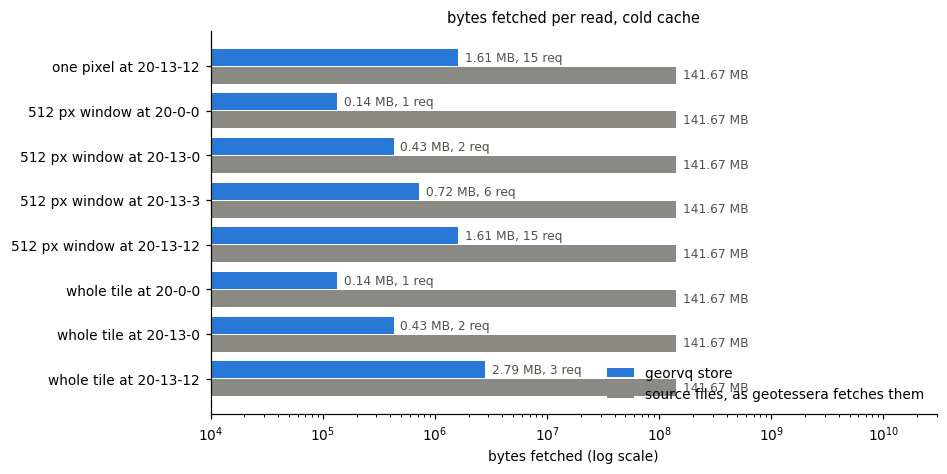

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 4.2), constrained_layout=True)
y = np.arange(len(costs))[::-1]
ax.barh(y + 0.2, costs["bytes"], height=0.38, color=BLUE, label="georvq store")
ax.barh(y - 0.2, costs["source_bytes"], height=0.38, color=GREY, label="source files, as geotessera fetches them")
for yy, (n, b) in zip(y, zip(costs["requests"], costs["bytes"])):
    ax.text(b * 1.15, yy + 0.2, f"{mb(b)}, {n} req", va="center", fontsize=8, color=INK)
for yy, b in zip(y, costs["source_bytes"]):
    ax.text(b * 1.15, yy - 0.2, mb(b), va="center", fontsize=8, color=INK)
ax.set_yticks(y, costs.index)
ax.set_xscale("log"); ax.set_xlim(1e4, 3e10)
ax.set_xlabel("bytes fetched (log scale)")
ax.legend(loc="lower right")
ax.set_title("bytes fetched per read, cold cache")
plt.show()

## How long a read takes over HTTP

This section times one cold read of the whole tile, from `georvq.open`
to the float32 array in memory, at four rungs, and the same tile read
from the source as geotessera reads it, by downloading its embedding
and scale files and loading them with numpy. The codec is loaded
beforehand and reused, so loading the weights is not timed.

Neither the coded sample nor the source can be timed where it will be
hosted: the sample is not yet published, and Tessera's bucket returns
404. A fair comparison therefore needs a stand-in for both. The first
cell measures the latency (time to first byte of small range requests)
and the single-stream throughput (one 16 MB range request) from this
machine to Hugging Face, using a large file already published there
(`PROBE_URL`, the AE v2 weights). With `SIMULATE_REMOTE = True`, the
coded store is then served from a local range server that waits that
latency before each response and limits each response to that
throughput. zarr-python makes the requests and the server records each
one; the georvq reader's own trace records the decode stages. The
source files are served from their local copies by a server with the
same latency and throughput, and are fetched with two concurrent
requests, one per file. With `SIMULATE_REMOTE = False` and `DATA_ROOT`
set to a URL, the same cell reads the hosted store through a forwarding
server, with no simulation, and the source is read the same way when
`SOURCE_ROOT` is a URL.

In [11]:
net = ae_demo_http.probe(PROBE_URL)
print(f"latency {net['latency_s'] * 1e3:.0f} ms (median of "
      f"{', '.join(f'{v * 1e3:.0f}' for v in net['ttfb_all_s'])} ms), "
      f"throughput {net['throughput_Bps'] / 1e6:.2f} MB/s over one "
      f"{net['large_bytes'] / 1e6:.0f} MB request")

latency 436 ms (median of 401, 415, 436, 568, 697 ms), throughput 41.38 MB/s over one 17 MB request


In [12]:
SPEED_RUNGS = ["20-0-0", "20-13-0", "20-13-3", "20-13-12"]
codec = ds.codec
servers = []
if SIMULATE_REMOTE:
    base, rec_g, srv_g = ae_demo_http.serve(root=DATA_ROOT, latency=net["latency_s"],
                                            bandwidth=net["throughput_Bps"])
else:
    base, rec_g, srv_g = ae_demo_http.serve(upstream=DATA_ROOT,
                                            headers=(STORAGE_OPTIONS or {}).get("headers"))
servers.append(srv_g)
speed_url = f"{base}/{TILE}.georvq.zarr"

runs = {}
for q in SPEED_RUNGS:
    tr = Trace()
    rec_g.clear()
    t0 = time.perf_counter()
    with georvq.open(speed_url, codec=codec, trace=tr) as d:
        a = d.read(quality=q)
    # the server's requests in place of the reader's per-array reads
    events = [e for e in tr.events if e["kind"] != "get"] + list(rec_g.events)
    runs[f"georvq {q}"] = {"t0": t0, "t1": time.perf_counter(), "events": events,
                           "bytes": sum(e["bytes"] for e in rec_g.events)}

if SOURCE_ROOT.startswith(("http://", "https://")):
    base_s, rec_s, srv_s = ae_demo_http.serve(upstream=SOURCE_ROOT)
else:
    base_s, rec_s, srv_s = ae_demo_http.serve(root=SOURCE_ROOT, latency=net["latency_s"],
                                              bandwidth=net["throughput_Bps"])
servers.append(srv_s)


def fetch(p):
    req = urllib.request.Request(f"{base_s}/{p}", headers={"User-Agent": "georvq-demo"})
    with urllib.request.urlopen(req) as r:
        return r.read()


t0 = time.perf_counter()
with ThreadPoolExecutor(2) as ex:
    blobs = list(ex.map(fetch, source_paths(TILE)))
t_got = time.perf_counter()
q_src, s_src = (np.load(io.BytesIO(b), allow_pickle=False) for b in blobs)
t1 = time.perf_counter()
runs["source .npy files"] = {"t0": t0, "t1": t1, "bytes": sum(e["bytes"] for e in rec_s.events),
                             "events": rec_s.events + [
                                 {"kind": "cpu", "label": "np.load", "t0": t_got, "t1": t1, "bytes": 0}]}
for s_ in servers:
    s_.shutdown()
assert np.array_equal(np.moveaxis(q_src, -1, 0), src.q)
for k, r in runs.items():
    n = sum(e["kind"] == "get" for e in r["events"])
    print(f"{k:<18} {r['t1'] - r['t0']:7.2f} s  {n:3d} requests  {mb(r['bytes'])}")

georvq 20-0-0         1.64 s    2 requests  0.19 MB
georvq 20-13-0        1.69 s    3 requests  0.48 MB
georvq 20-13-3        4.75 s   11 requests  1.07 MB
georvq 20-13-12      12.76 s   29 requests  2.84 MB
source .npy files     3.78 s    2 requests  141.67 MB


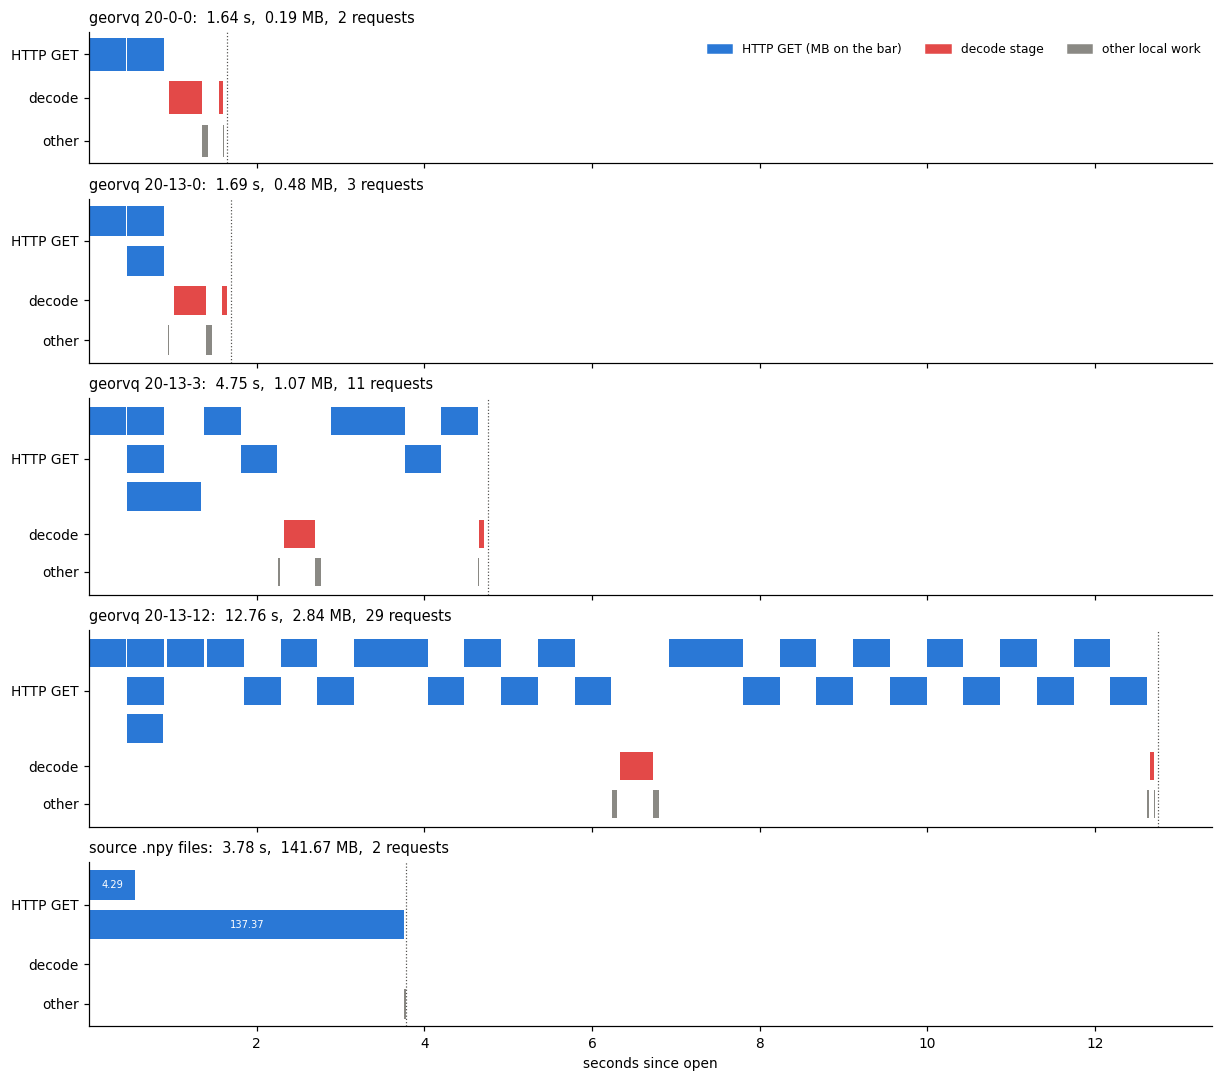

,mean channel (ms),codebook lookup (ms),decoder forward (ms),postprocess (ms)
read,,,,
georvq 20-0-0,1.9,1.6,115.9,327.4
georvq 20-13-0,1.9,2.3,115.8,318.6
georvq 20-13-3,1.9,3.3,115.5,303.8
georvq 20-13-12,1.9,7.1,115.5,324.4


In [13]:
COLOURS = {"get": BLUE, "decode": RED, "cpu": GREY}


def lanes(events):
    """Greedy lane assignment so overlapping events do not cover each other."""
    ends, out = [], []
    for e in sorted(events, key=lambda e: e["t0"]):
        for i, end in enumerate(ends):
            if e["t0"] >= end:
                ends[i] = e["t1"]; out.append((i, e)); break
        else:
            ends.append(e["t1"]); out.append((len(ends) - 1, e))
    return out, len(ends)


groups = {k: {kind: lanes([e for e in r["events"] if e["kind"] == kind])
              for kind in ("get", "decode", "cpu")} for k, r in runs.items()}
heights = [sum(max(n, 1) for _, n in g.values()) + 1 for g in groups.values()]
t_max = max(r["t1"] - r["t0"] for r in runs.values())
fig, axes = plt.subplots(len(runs), 1, figsize=(11, 0.32 * sum(heights) + 1.4), sharex=True,
                         gridspec_kw={"height_ratios": heights}, constrained_layout=True)
for ax, (k, r) in zip(axes, runs.items()):
    row, ticks = 0, []
    for kind in ("get", "decode", "cpu"):
        placed, n = groups[k][kind]
        for lane, e in placed:
            x0, w = e["t0"] - r["t0"], max(e["t1"] - e["t0"], 1e-3)
            ax.barh(row + lane, w, left=x0, height=0.75, color=COLOURS[kind], lw=0)
            if kind == "get" and w > 0.04 * t_max:
                ax.text(x0 + w / 2, row + lane, mb(e["bytes"]).replace(" MB", ""), ha="center",
                        va="center", fontsize=6.5, color="white")
        ticks.append((row + (max(n, 1) - 1) / 2, {"get": "HTTP GET", "decode": "decode",
                                                    "cpu": "other"}[kind]))
        row += max(n, 1)
    ax.set_yticks([t for t, _ in ticks], [l for _, l in ticks])
    ax.invert_yaxis()
    ax.set_title(f"{k}:  {r['t1'] - r['t0']:.2f} s,  {mb(r['bytes'])},  "
                 f"{sum(e['kind'] == 'get' for e in r['events'])} requests", loc="left")
    ax.axvline(r["t1"] - r["t0"], color=INK, lw=0.8, ls=":")
axes[-1].set_xlabel("seconds since open")
axes[0].legend(handles=[Rectangle((0, 0), 1, 1, color=c) for c in COLOURS.values()],
               labels=["HTTP GET (MB on the bar)", "decode stage", "other local work"],
               loc="upper right", ncol=3, fontsize=8)
plt.show()

stages = pd.DataFrame([{**{"read": k}, **{lab: sum(e["t1"] - e["t0"] for e in r["events"]
                                               if e["label"] == lab)
                                           for lab in ("mean channel", "codebook lookup",
                                                       "decoder forward", "postprocess")}}
                       for k, r in runs.items() if k.startswith("georvq")]).set_index("read")
(stages * 1e3).round(1).rename(columns=lambda c: c + " (ms)")

## Reading to a quality bound

Instead of a rung, `read` accepts a bound on a quality statistic, such
as `quality="p99<=0.4"`. The reader looks up each window's measured
errors in the quality array and decodes every window at the cheapest
rung that meets the bound, or at full depth where none does. The map
shows the rung chosen for each window of the tile. Within one read the
reader fetches each tier at the deepest level any window in the read
needs, so the bytes fetched sit between the ideal per-window cost and
the full-depth cost, plus the quality array. On this tile 25% of the
windows are read at full depth, and for 19% no rung meets the bound at
all, so a read of the whole tile fetches all of its records. The quality values
are coded in steps of 7.5%, so a window read at the cheapest rung that
meets the bound can measure up to 3.7% above it when decoded.

whole tile at p99<=0.4: 0.90 MB of records chosen per window, against 1.45 MB at 20-13-12
fetched: 2.87 MB in 29 requests at p99<=0.4, against 2.79 MB at 20-13-12
windows meeting the bound when decoded here: 33.3%, within the coding step of it: 89.6% (worst p99 0.530)
windows chosen at full depth: 25.3%, of which no rung meets the bound in the quality array: 18.8% of all windows


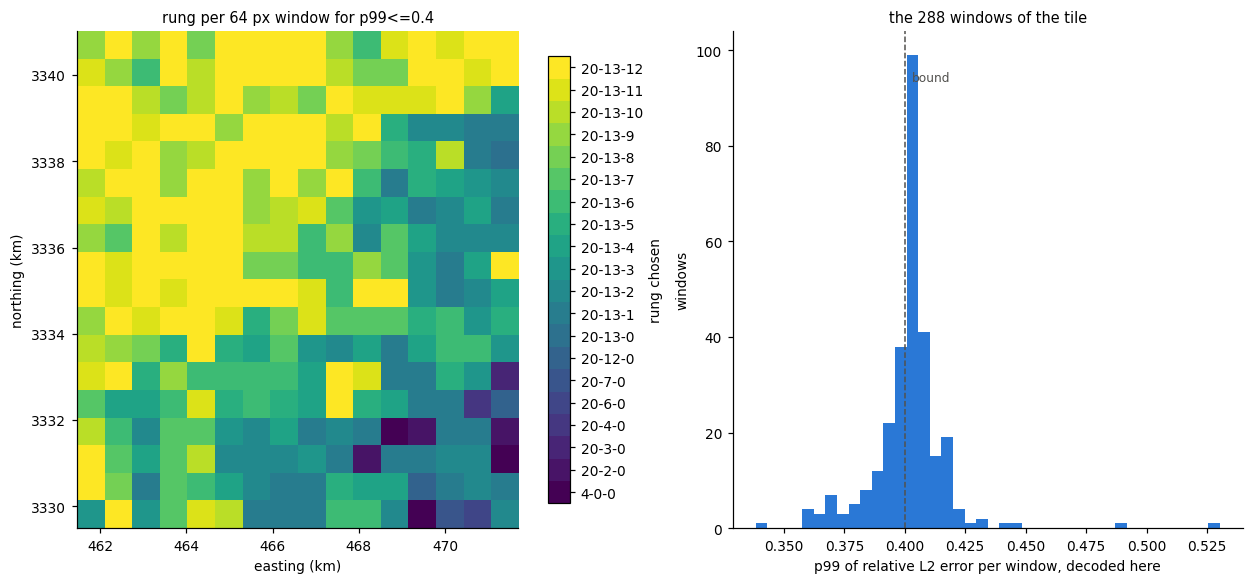

In [14]:
BOUND = "p99<=0.4"
rmap = ds.window_rungs(BOUND)                               # whole tile, north-up window grid
bits = np.array([r["bits_window"] for r in ds.header["rungs"]])
names = ["-".join(map(str, r)) for r in ds.rungs]
used = np.unique(rmap)

d_q = cost(lambda d: d.read(quality=BOUND))
a_q = ds.read(quality=BOUND)
e_q = np.full((gh * W, gw * W), np.nan)
e_q[:ds.height, :ds.width] = np.where(valid_ref, err(x_ref, vec(a_q)), np.nan)
e_w = e_q.reshape(gh, W, gw, W).transpose(0, 2, 1, 3).reshape(gh, gw, -1)
p99_w = np.nanquantile(e_w, 0.99, axis=-1)

print(f"whole tile at {BOUND}: {bits[rmap].sum() / 8 / 1e6:.2f} MB of records chosen per window, "
      f"against {rmap.size * bits[-1] / 8 / 1e6:.2f} MB at 20-13-12")
print(f"fetched: {mb(d_q[1])} in {d_q[0]} requests at {BOUND}, "
      f"against {mb(costs.loc['whole tile at 20-13-12', 'bytes'])} at 20-13-12")
print(f"windows meeting the bound when decoded here: {(p99_w <= 0.4).mean():.1%}, "
      f"within the coding step of it: {(p99_w <= 0.4 * 10 ** (0.5 / qh['scale'])).mean():.1%} "
      f"(worst p99 {np.nanmax(p99_w):.3f})")
print(f"windows chosen at full depth: {(rmap == n_r - 1).mean():.1%}, of which no rung "
      f"meets the bound in the quality array: "
      f"{(quality_value(qc[..., 2 * n_r - 1], qh['scale'], qh['offset']) > 0.4).mean():.1%} of all windows")

cmap = plt.get_cmap("viridis", len(used))
lut = np.zeros(len(ds.rungs), int); lut[used] = np.arange(len(used))
fig, ax = plt.subplots(1, 2, figsize=(12, 5.2), constrained_layout=True,
                       gridspec_kw={"width_ratios": [1.15, 1]})
x0, y0, x1, y1 = corners(ds.transform, gh * W, gw * W)
im = ax[0].imshow(lut[rmap], cmap=cmap, vmin=-0.5, vmax=len(used) - 0.5,
                  extent=[x0 / 1e3, x1 / 1e3, y0 / 1e3, y1 / 1e3], interpolation="nearest")
cb = fig.colorbar(im, ax=ax[0], ticks=np.arange(len(used)), shrink=0.9)
cb.ax.set_yticklabels([names[i] for i in used]); cb.set_label("rung chosen")
ax[0].set_xlabel("easting (km)"); ax[0].set_ylabel("northing (km)")
ax[0].set_title(f"rung per 64 px window for {BOUND}")
ax[1].hist(p99_w.ravel(), bins=40, color=BLUE)
ax[1].axvline(0.4, color=INK, ls="--", lw=1)
ax[1].text(0.403, ax[1].get_ylim()[1] * 0.9, "bound", color=INK, fontsize=8)
ax[1].set_xlabel("p99 of relative L2 error per window, decoded here")
ax[1].set_ylabel("windows")
ax[1].set_title(f"the {rmap.size} windows of the tile")
plt.show()

## Similarity search and clustering

Two common uses of the embeddings, run on the source tile and on
reconstructions at four rungs. The search takes the embedding of one
pixel (marked) and maps its Euclidean distance to every pixel of the
tile; each product is queried with its own pixel, as a user holding
only that product would. The clustering fits k-means with 8 clusters
on the source and assigns the pixels of every product to the same
centroids. The table reports the correlation of each distance map
with the source's, the share of the source's 1% nearest pixels that
are also among the reconstruction's 1% nearest, and the share of
pixels assigned to the same cluster.

In [15]:
from sklearn.cluster import KMeans

QUERY = (500, 400)                       # row, column in the tile
SHOW = ["20-0-0", "20-13-0", "20-13-3", "20-13-12"]
prods = {"source": x_ref} | {q: vec(dec[q]) for q in SHOW}

X = x_ref[valid_ref]
km = KMeans(8, n_init=4, random_state=0).fit(
    X[np.random.default_rng(0).choice(len(X), 50_000, replace=False)])
dists, labels, rows = {}, {}, []
for k, u in prods.items():
    s = np.linalg.norm(np.nan_to_num(u) - u[QUERY], axis=-1).astype(np.float32)
    s[~valid_ref] = np.nan
    lab = np.full(valid_ref.shape, -1)
    lab[valid_ref] = km.predict(np.nan_to_num(u[valid_ref]))
    dists[k], labels[k] = s, lab
near = lambda s: s <= np.nanquantile(s, 0.01)
for k in SHOW:
    rows.append({"rung": k,
                 "distance r": np.corrcoef(dists["source"][valid_ref], dists[k][valid_ref])[0, 1],
                 "nearest 1% recall": (near(dists["source"]) & near(dists[k])).sum() / near(dists["source"]).sum(),
                 "same cluster": (labels[k] == labels["source"])[valid_ref].mean()})
pd.DataFrame(rows).set_index("rung").style.format("{:.3f}")

,distance r,nearest 1% recall,same cluster
rung,,,
20-0-0,0.780,0.104,0.652
20-13-0,0.920,0.364,0.803
20-13-3,0.948,0.457,0.882
20-13-12,0.968,0.572,0.920


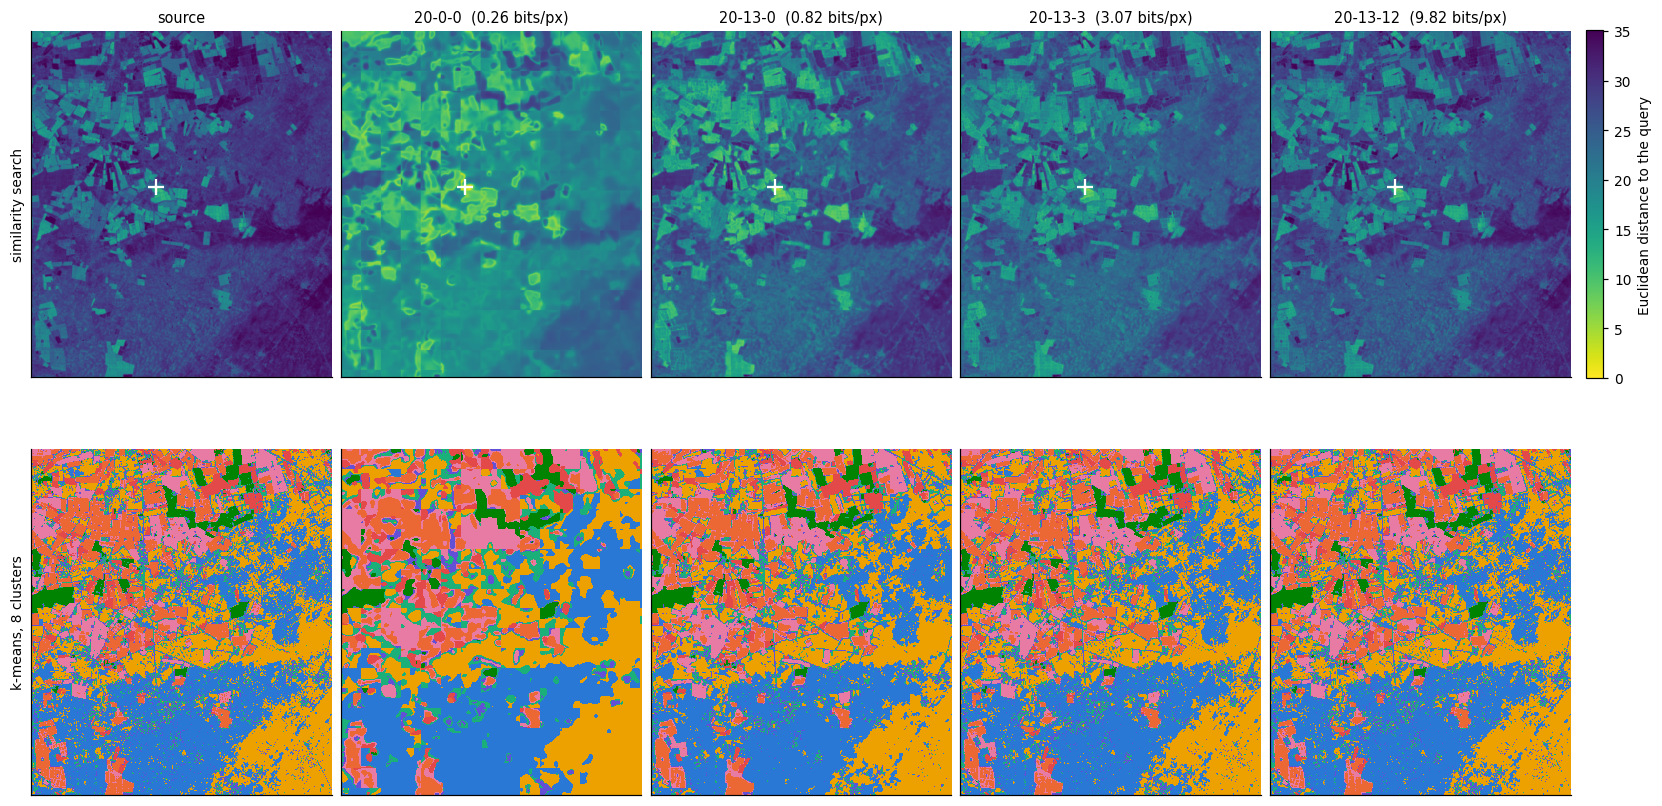

In [16]:
fig, ax = plt.subplots(2, 5, figsize=(15, 7.6), constrained_layout=True)
qx, qy = ds.transform * (QUERY[1] + 0.5, QUERY[0] + 0.5)
ccmap = ListedColormap([BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED])
vmax = np.nanquantile(dists["source"], 0.99)
for j, (k, s) in enumerate(dists.items()):
    im = show(ax[0, j], s, ds.transform, ticks=False, cmap="viridis_r", vmin=0, vmax=vmax)
    ax[0, j].plot(qx / 1e3, qy / 1e3, "+", color="white", ms=10, mew=1.5)
    ax[0, j].set_title(k if k == "source" else f"{k}  ({scores.loc[k, 'bits_px']:.2f} bits/px)")
    show(ax[1, j], np.ma.masked_less(labels[k], 0), ds.transform, ticks=False, cmap=ccmap,
         vmin=-0.5, vmax=7.5, interpolation="nearest")
fig.colorbar(im, ax=ax[0, :], shrink=0.85, pad=0.01, label="Euclidean distance to the query")
ax[0, 0].set_ylabel("similarity search"); ax[1, 0].set_ylabel("k-means, 8 clusters")
plt.show()

## Nodata and tile edges

A geotessera pixel is nodata where its vector is all zero or its scale
is not between 0 and 1. The store keeps the tile's validity mask once,
losslessly, and the reader writes zero vectors back wherever it is
unset, so nodata comes back exactly. A window with no valid pixel is
not coded, and a chunk with none is not stored, which makes partial
tiles smaller. Tiles are not multiples of the 64 px window, so the last
row and column of windows extend past the tile; the pixels beyond it
are coded as invalid, and the mask restores the tile's extent. The four
sample tiles are fully valid, so the cell below checks the mask against
the source and compares the error in the partly filled edge windows
with the rest of the tile, rather than showing a partly valid tile.

In [17]:
v_src = raw_valid(src.q, src.s)
nod_dec = (full == 0).all(0)
empty = {g["kind"]: len(g.get("empty_chunks", [])) for g in ds.header["layout"]["groups"]}
edge = np.zeros(mask.shape, bool)
edge[(gh - 1) * W:, :] = True
edge[:, (gw - 1) * W:] = True
e3 = err(x_ref, vec(dec["20-13-3"]))

print(f"valid pixels {mask.mean():.1%}; the store's mask and the source's validity differ at "
      f"{(mask != v_src).sum()} pixels")
print(f"nodata pixels: {(~v_src).sum():,} in the source, {nod_dec.sum():,} decoded; "
      f"empty chunks per kind: {empty}")
print(f"tile {ds.height} x {ds.width} px, coded as {gh} x {gw} windows ({gh * W} x {gw * W} px); "
      f"the last row of windows holds {ds.height - (gh - 1) * W} rows of the tile, "
      f"the last column {ds.width - (gw - 1) * W} columns")
print(f"mean relative L2 at 20-13-3: {e3[edge & valid_ref].mean():.4f} in the last row and column "
      f"of windows, {e3[~edge & valid_ref].mean():.4f} elsewhere")

valid pixels 100.0%; the store's mask and the source's validity differ at 0 pixels
nodata pixels: 0 in the source, 0 decoded; empty chunks per kind: {'base': 0, 'mid': 0, 'fine': 0, 'quality': 0}
tile 1111 x 966 px, coded as 18 x 16 windows (1152 x 1024 px); the last row of windows holds 23 rows of the tile, the last column 6 columns
mean relative L2 at 20-13-3: 0.2493 in the last row and column of windows, 0.2783 elsewhere


## The tile index

`tessera_georvq_index.parquet` has one row per coded store: geotessera's
manifest row for the tile (year, centre longitude and latitude, the
source files' paths, sizes and dates), the store's path, its codec ids,
its size, and the bytes a whole-tile read fetches at each rung. pyarrow,
pandas or DuckDB can query it without opening the coded stores. The
`grid_path` and `scales_path` columns point at the source tile in
Tessera's bucket, not at the stores.

4 tiles; columns: year, lon_i, lat_i, version, variant, lon, lat, directory, grid_path, scales_path, grid_mtime, scales_mtime, grid_size, scales_size, path, bitstream_id, decoder_id, store_bytes, metadata_bytes, quality_bytes, rungs
in the box: ['2024/grid_-9.45_30.15.georvq.zarr', '2024/grid_-9.45_30.25.georvq.zarr']
duckdb is not installed; the same query works with read_parquet() in DuckDB


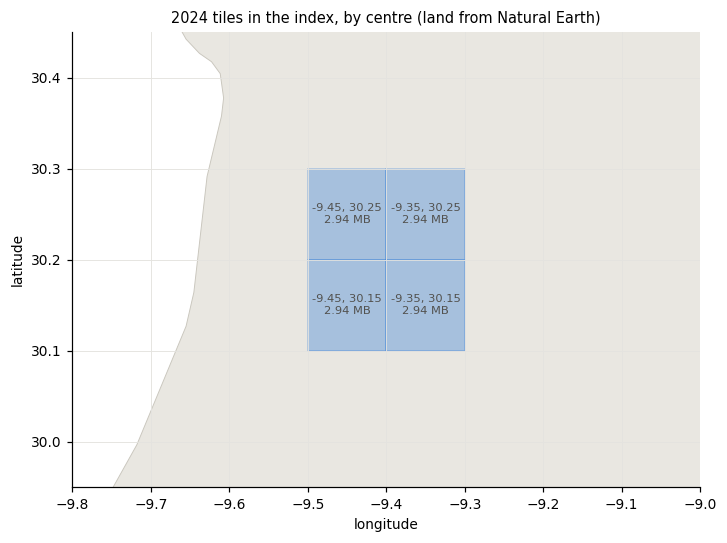

,year,tile,lon,lat,store MB,20-13-0 MB,source MB
0,2024,grid_-9.35_30.15,-9.35,30.15,2.94,0.43,141.67
1,2024,grid_-9.35_30.25,-9.35,30.25,2.94,0.43,141.52
2,2024,grid_-9.45_30.15,-9.45,30.15,2.94,0.43,141.94
3,2024,grid_-9.45_30.25,-9.45,30.25,2.94,0.43,141.79


In [18]:
import pyarrow.compute as pc

idx = index                                  # read with the helpers above, from idx_path
print(f"{idx.num_rows} tiles; columns: {', '.join(idx.column_names)}")

def at(rungs, name):
    return next(r["bytes"] for r in rungs if r["rung"] == name)

tiles = pd.DataFrame({
    "year": idx["year"].to_pylist(),
    "tile": [p.rsplit("/", 1)[-1].split(".georvq")[0] for p in idx["path"].to_pylist()],
    "lon": idx["lon"].to_pylist(), "lat": idx["lat"].to_pylist(),
    "store MB": [(b + m) / 1e6 for b, m in zip(idx["store_bytes"].to_pylist(),
                                               idx["metadata_bytes"].to_pylist())],
    "20-13-0 MB": [at(r, "20-13-0") / 1e6 for r in idx["rungs"].to_pylist()],
    "source MB": [(g + s) / 1e6 for g, s in zip(idx["grid_size"].to_pylist(),
                                                idx["scales_size"].to_pylist())]})

# tiles whose 0.1 degree cell intersects a box
box = dict(west=-9.5, south=30.0, east=-9.4, north=30.4)
sel = idx.filter(pc.and_(pc.and_(pc.greater(pc.add(idx["lon"], 0.05), box["west"]),
                                 pc.less(pc.subtract(idx["lon"], 0.05), box["east"])),
                         pc.and_(pc.greater(pc.add(idx["lat"], 0.05), box["south"]),
                                 pc.less(pc.subtract(idx["lat"], 0.05), box["north"]))))
print(f"in the box: {sel['path'].to_pylist()}")
try:
    import duckdb
    print(duckdb.sql(f"select year, lon, lat, store_bytes from read_parquet('{idx_path}') "
                     "order by store_bytes").df())
except ImportError:
    print("duckdb is not installed; the same query works with read_parquet() in DuckDB")

fig, ax = plt.subplots(figsize=(6.5, 4.8), constrained_layout=True)
try:
    import geopandas as gpd
    land = gpd.read_file("https://naciscdn.org/naturalearth/10m/physical/ne_10m_land.zip")
    land.plot(ax=ax, color="#e9e7e1", edgecolor="#c9c6bd", lw=0.6, zorder=0)
except Exception as e:                       # no geopandas or no network: footprints only
    print(f"no basemap ({type(e).__name__})")
for _, t in tiles.iterrows():
    ax.add_patch(Rectangle((t["lon"] - 0.05, t["lat"] - 0.05), 0.1, 0.1, fill=True,
                           fc=BLUE, alpha=0.35, ec=BLUE, lw=1))
    ax.annotate(f"{t['lon']:.2f}, {t['lat']:.2f}\n{t['store MB']:.2f} MB", (t["lon"], t["lat"]),
                ha="center", va="center", fontsize=7.5, color=INK)
ax.set_xlim(-9.8, -9.0); ax.set_ylim(29.95, 30.45)
ax.grid(True, color="#e4e3df", lw=0.6, zorder=-1)
ax.set_aspect(1.16)                    # a degree of longitude is 0.86 of a degree of latitude here
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title("2024 tiles in the index, by centre (land from Natural Earth)")
plt.show()
tiles.round(2)

## Writing a GeoTIFF, and decoding without torch

`ds.profile` is a GeoTIFF profile for the decoded output (CRS,
transform, float32 bands, nodata 0, block size, compression), so a
decoded window can be written as a GeoTIFF as below. For a whole tile,
`georvq.inference.store_dataset.reconstruct(ds, "out.tif",
quality="20-13-3")` does the same in strips. For code that reads
geotessera's arrays, `georvq.tessera.v2.to_geotessera` turns a decoded
array back into int8 codes of shape (rows, cols, 128) and a float32
scale per pixel, set so that every valid pixel has a code of 127 or
-127, as in the distributed tiles.

`backend="onnx"` decodes with onnxruntime and numpy from the ONNX
export in the bundle, without torch. It decodes in fp32. On CUDA the
torch backend decodes in bf16 by default, so the comparison below is
made against both the bf16 decode used above and an fp32 torch decode
(`bf16=False`).

In [19]:
out = os.path.join(tempfile.mkdtemp(), "window_20-13-3.tif")
a_win = dec["20-13-3"][:, WINDOW.row_off:WINDOW.row_off + WINDOW.height,
                       WINDOW.col_off:WINDOW.col_off + WINDOW.width]
prof = dict(ds.profile, width=WINDOW.width, height=WINDOW.height, transform=win_t,
            blockxsize=512, blockysize=512)
with rasterio.open(out, "w", **prof) as dst:
    dst.write(a_win)
    dst.update_tags(**ds.tags())
with rasterio.open(out) as chk:
    print(f"{out}: {chk.width} x {chk.height}, {chk.count} bands of {chk.dtypes[0]}, "
          f"{chk.crs.to_string()}, {chk.profile.get('compress')}, {mb(os.path.getsize(out))}; "
          f"identical to the array: {np.array_equal(chk.read(), a_win)}")

q8, s8 = to_geotessera(dec["20-13-3"])
x8 = q8.astype(np.float32) * s8[..., None]
x8[~valid_ref] = np.nan
print(f"to_geotessera: int8 {q8.shape} codes and float32 {s8.shape} scales, {mb(q8.nbytes + s8.nbytes)}; "
      f"mean relative L2 {err(vec(dec['20-13-3']), x8)[valid_ref].mean():.4f} against the decoded "
      f"floats, {err(x_ref, x8)[valid_ref].mean():.4f} against the source "
      f"(the decoded floats: {scores.loc['20-13-3', 'mean']:.4f})")

t = time.perf_counter()
with open_tile(TILE, backend="onnx") as dx:
    a_onnx = dx.read(quality="20-13-3")
t_onnx = time.perf_counter() - t
a_torch = dec["20-13-3"]
with open_tile(TILE, bf16=False) as d32:
    a_fp32 = d32.read(quality="20-13-3")
print(f"onnx backend, CPU: {t_onnx:.1f} s including loading the graphs")
for name, a in [("torch bf16", a_torch), ("torch fp32", a_fp32)]:
    d = err(vec(a), vec(a_onnx))[valid_ref]
    print(f"onnx against {name}: relative L2 difference mean {d.mean():.2e}, largest {d.max():.2e}; "
          f"largest absolute difference {np.abs(a_onnx - a).max():.2e}")
print(f"mean relative L2 against the source: onnx {err(x_ref, vec(a_onnx))[valid_ref].mean():.5f}, "
      f"torch bf16 {err(x_ref, vec(a_torch))[valid_ref].mean():.5f}, "
      f"torch fp32 {err(x_ref, vec(a_fp32))[valid_ref].mean():.5f}")

/tmp/tmp_uygktc4/window_20-13-3.tif: 512 x 512, 128 bands of float32, EPSG:32629, zstd, 47.46 MB; identical to the array: True


to_geotessera: int8 (1111, 966, 128) codes and float32 (1111, 966) scales, 141.67 MB; mean relative L2 0.0064 against the decoded floats, 0.2776 against the source (the decoded floats: 0.2775)


onnx backend, CPU: 31.9 s including loading the graphs


onnx against torch bf16: relative L2 difference mean 5.07e-03, largest 2.22e-02; largest absolute difference 1.61e-01


onnx against torch fp32: relative L2 difference mean 2.56e-04, largest 1.56e-03; largest absolute difference 1.23e-02


mean relative L2 against the source: onnx 0.27744, torch bf16 0.27748, torch fp32 0.27744
